# Practical 1 report: preparing biological data for machine learning

**Student:** Anna Gurina  
**Date:** 21-Sep-2026  
**Practical:** 1 - Data to ML-ready format

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

DATA = Path(".")
RANDOM_STATE = 100926

mice_raw = pd.read_excel(DATA / "Data_Cortex_Nuclear.xls")
metadata_cols = ["MouseID", "Genotype", "Treatment", "Behavior", "class"]
protein_cols = [c for c in mice_raw.columns if c not in metadata_cols]
mice_raw["mouse_id"] = mice_raw["MouseID"].str.split("_").str[0]

print("Mice raw:", mice_raw.shape)

Mice raw: (1080, 83)


## 2. Data-preparation readiness

Complete this section before describing modelling results.

## Scientific purpose and provenance

- [x] Is the biological question and prediction task stated clearly? Yes, as per the paper, the aim is to identify subsets of proteins that are discriminant between the classes.
- [x] Is the unit of observation clear (for example, patient, tissue, cell, mouse, or technical measurement)? The file with dataset lacks information, however it's described in the paper it was taken from (https://www.semanticscholar.org/reader/5c5754b02a4f2f36ccf8cdda78059cdb19860532), as well as in the dataset download source itself (https://archive.ics.uci.edu/dataset/342/mice+protein+expression).
- [x] Have I recorded the data version, processing history, and transformations already applied? 
We have a note on Missing Values presence per feature. Also we have a statement that measurements are independent.

In [2]:
mice_raw.head()

,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,...,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class,mouse_id
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,...,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m,309
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,...,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m,309
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,...,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m,309
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,...,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m,309
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,...,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m,309


## Table shape and identifiers

- [x] Is the table tidy: one observation per row, one variable per column, and one value per cell? 
Yes
- [x] If the original assay has features in rows and samples in columns, have I transposed it into the format expected by the analysis tool? Samples are already in rows, proteins in columns.
- [x] Are row names, column names, and identifiers clear, unique, stable, and free from accidental index columns? MouseID is unique
- [x] Can every feature and observation be traced back to its source? Yes, through MouseID + protein names.
- [x] Are the feature matrix and metadata aligned by an explicit identifier rather than by row order? Yes, we have Genotype, Treatment, Behavior, class per mouse ID.

In [3]:
print("Shape:", mice_raw.shape)
print("Column names are unique:", mice_raw.columns.is_unique)
print("MouseID is unique:", mice_raw["MouseID"].is_unique)
print("Metadata columns:", metadata_cols)
print("Protein-expression columns:", len(protein_cols))

Shape: (1080, 83)
Column names are unique: True
MouseID is unique: True
Metadata columns: ['MouseID', 'Genotype', 'Treatment', 'Behavior', 'class']
Protein-expression columns: 77


## Types, values, and measurement meaning

- [x] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified? Yes: proteins are `float64`; `MouseID` and the four metadata columns are text categories.
- [x] Are units, scales, encodings, reference categories, and detection limits understood? Not from the source file, but from the paper.
- [x] Have I checked impossible values, inconsistent labels, unexpected categories, constant features, and extreme values? Yes, in 3.3 Diagnostics.
- [ ] Are normalization, scaling, log transformation, and batch-correction steps documented? No.

In [4]:
mice_raw.info()
print("Constant columns:", [column for column in mice_raw.columns if mice_raw[column].nunique(dropna=False) <= 1])

<class 'pandas.DataFrame'>
RangeIndex: 1080 entries, 0 to 1079
Data columns (total 83 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MouseID          1080 non-null   str    
 1   DYRK1A_N         1077 non-null   float64
 2   ITSN1_N          1077 non-null   float64
 3   BDNF_N           1077 non-null   float64
 4   NR1_N            1077 non-null   float64
 5   NR2A_N           1077 non-null   float64
 6   pAKT_N           1077 non-null   float64
 7   pBRAF_N          1077 non-null   float64
 8   pCAMKII_N        1077 non-null   float64
 9   pCREB_N          1077 non-null   float64
 10  pELK_N           1077 non-null   float64
 11  pERK_N           1077 non-null   float64
 12  pJNK_N           1077 non-null   float64
 13  PKCA_N           1077 non-null   float64
 14  pMEK_N           1077 non-null   float64
 15  pNR1_N           1077 non-null   float64
 16  pNR2A_N          1077 non-null   float64
 17  pNR2B_N          1077 non

## Missing values

- [x] Have I detected missing values using the dataset's actual missing-value representations, not only `NaN`? Yes, in source file missing values appear empty, parsed as NaN by pandas.
- [x] Have I measured missingness by row, column, group, and relevant batch or time variable? Yes, in 3.3 Diagnostics. No batch/time variable.
- [x] Do I know whether missingness is structural, technical, or plausibly related to the biology or target? Missing amount of proteins differs between classes.
- [x] Have I justified whether to retain, remove, or impute missing values? There're many missing values, so impute with median, bot to lose data.
- [x] If imputing, will the imputer be fitted on training data only and then applied to validation/test data? Yes

Total missing protein values: 1396 of 83160
Proteins with missing values: 49
Samples with missing values: 528
Missing metadata values: 0


BCL2_N        285
H3MeK4_N      270
BAD_N         213
EGR1_N        210
H3AcK18_N     180
pCFOS_N        75
ELK_N          18
Bcatenin_N     18
dtype: int64

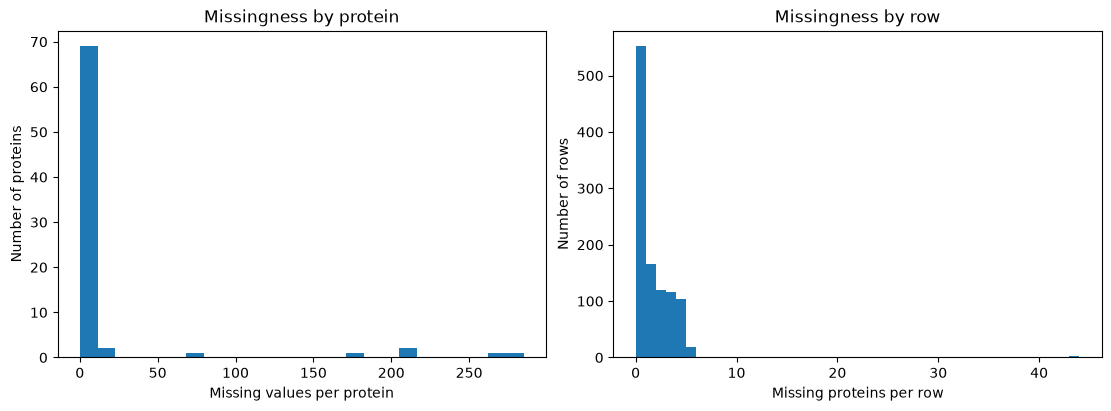

In [16]:
missing_by_column = mice_raw[protein_cols].isna().sum()
missing_by_row = mice_raw[protein_cols].isna().sum(axis=1)

print("Total missing protein values:", int(missing_by_column.sum()), "of", mice_raw[protein_cols].size)
print("Proteins with missing values:", int((missing_by_column > 0).sum()))
print("Samples with missing values:", int((missing_by_row > 0).sum()))
print("Missing metadata values:", int(mice_raw[metadata_cols].isna().sum().sum()))

display(missing_by_column[missing_by_column > 0].sort_values(ascending=False).head(8))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

axes[0].hist(missing_by_column, bins=25)
axes[0].set_xlabel("Missing values per protein")
axes[0].set_ylabel("Number of proteins")
axes[0].set_title("Missingness by protein")

axes[1].hist(missing_by_row, bins=range(0, int(missing_by_row.max()) + 2))
axes[1].set_xlabel("Missing proteins per row")
axes[1].set_ylabel("Number of rows")
axes[1].set_title("Missingness by row")
plt.show()

## Replicates, dependence, and grouping

- [ ] Have I checked for exact duplicates and near-duplicate observations? Exact duplicates: none. Near-duplicates: not checked.
- [x] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples? Repeated measurements: each mouse is measured 15 times.
- [x] Is the independent biological unit identified by a grouping variable? Yes: `mouse_id`, prefix of `MouseID`.
- [x] Will all related observations and their derivatives remain in the same train/validation/test split? Yes, group-aware split on `mouse_id`.
- [x] If I created augmented or synthetic observations, is their provenance recorded and reproducible? None created.

In [6]:
print("Duplicate MouseIDs:", mice_raw["MouseID"].duplicated().sum())
print("Duplicate full rows:", mice_raw.duplicated().sum())
print("Unique mice:", mice_raw["mouse_id"].nunique())

Duplicate MouseIDs: 0
Duplicate full rows: 0
Unique mice: 72


## Target, leakage, and study design

- [x] Is the target defined before modelling, with its classes or values checked for balance and validity? Yes
- [x] Have I excluded identifiers, post-outcome variables, duplicated target information, and other leakage sources from the features? Yes: `MouseID`, `mouse_id`, `class`.
- [x] Have I identified batch, site, plate, subject, cohort, treatment, sex, age, time, or other possible confounders? `Treatment`, `Behavior`, `class`.
- [x] Have I checked whether the target is associated with a technical or grouping variable? See 3.6 Confounding and distribution structure.
- [x] Does the planned split represent the biological generalization question? Yes: a split by mouse tests generalization to new mice.

In [7]:
y_mice = mice_raw["Genotype"].copy()
y_mice.value_counts()

Genotype
Control    570
Ts65Dn     510
Name: count, dtype: int64

## Reproducibility and decision record

- [x] Are random seeds, software versions, file names, and input/output shapes recorded? Yes
- [x] Are all preprocessing steps placed in a reproducible pipeline? Yes, through the notebook.
- [x] Have I recorded unresolved data-quality concerns and the decisions made about them? Yes
- [x] Can another person explain what each row, column, feature, target, and grouping variable means? Yes

In [8]:
print("Random seed:", RANDOM_STATE)
print("numpy:", np.__version__, " pandas:", pd.__version__, " scikit-learn:", sklearn.__version__)
print("Input file: Data_Cortex_Nuclear.xls")
print("Raw data shape:", mice_raw.shape)

Random seed: 100926
numpy: 2.4.6  pandas: 3.0.5  scikit-learn: 1.9.0
Input file: Data_Cortex_Nuclear.xls
Raw data shape: (1080, 83)


### 3.1 Data presentation

Describe:
- what one row represents 
- what one biological mouse represents 
- `MouseID` and derived `mouse_id` 
- `Genotype`, `Treatment`, `Behavior`, and `class` 
- the prediction target selected.

**Answers:**  
- One row: 1 measurement of expressions of 77 proteins for 1 mouse.
- One biological mouse: 15 rows - 1 mouse was measured 15 times
- `MouseID`: 1 measurement (out of 15) for 1 mouse.
- `Genotype`: Control or Ts65Dn (trisomic).
- `Treatment`: Memantine or Saline
- `Behavior`: context-shock (C/S) or shock-context (S/C) learning
- `class`: the combination of all 3 factors.
- Target: `Genotype`, Control/Ts65Dn based on protein expressions (features)

In [9]:
mice_raw[["MouseID", "mouse_id", "Genotype", "Treatment", "Behavior", "class"]].head(3)

mice_raw[["Genotype", "Treatment", "Behavior", "class"]].drop_duplicates().sort_values("class")

,Genotype,Treatment,Behavior,class
0,Control,Memantine,C/S,c-CS-m
300,Control,Saline,C/S,c-CS-s
150,Control,Memantine,S/C,c-SC-m
435,Control,Saline,S/C,c-SC-s
570,Ts65Dn,Memantine,C/S,t-CS-m
840,Ts65Dn,Saline,C/S,t-CS-s
705,Ts65Dn,Memantine,S/C,t-SC-m
945,Ts65Dn,Saline,S/C,t-SC-s


### 3.2 Tidy-data assessment and EDA

Report:
- rows and columns: 1080 rows x 83 columns
- unique mice: 72
- measurements per mouse: 15 
- categories and counts for Genotype, Treatment, Behavior, and class: 
  - Genotype Control 570 / Ts65Dn 510
  - Treatment Memantine 570 / Saline 510
  - Behavior S/C 555 / C/S 525
  - class 8 values with 105-150 rows each 
- whether the table is tidy: yes - 1 measurement per row and 1 protein per column. However, class is the duplication for `Genotype`, `Treatment`, `Behavior`.

Include at least three plots. For each, state the biological question it addresses.

Rows and columns: (1080, 83)
Unique mice: 72
Measurements per mouse: [15]

Genotype
Genotype
Control    570
Ts65Dn     510
Name: count, dtype: int64

Treatment
Treatment
Memantine    570
Saline       510
Name: count, dtype: int64

Behavior
Behavior
S/C    555
C/S    525
Name: count, dtype: int64

class
class
c-CS-m    150
c-SC-m    150
c-CS-s    135
c-SC-s    135
t-CS-m    135
t-SC-m    135
t-SC-s    135
t-CS-s    105
Name: count, dtype: int64


,mice,rows
class,,
c-CS-m,10,150
c-CS-s,9,135
c-SC-m,10,150
c-SC-s,9,135
t-CS-m,9,135
t-CS-s,7,105
t-SC-m,9,135
t-SC-s,9,135


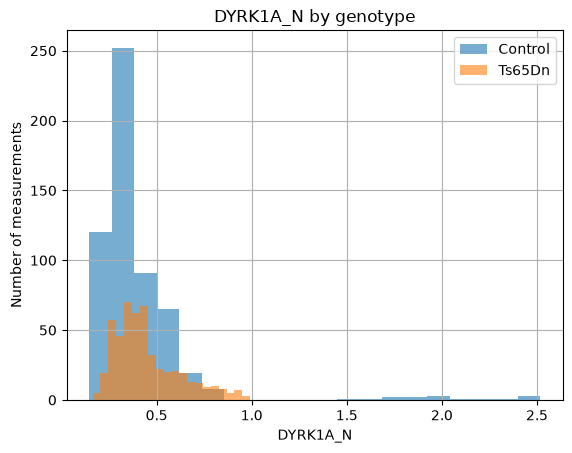

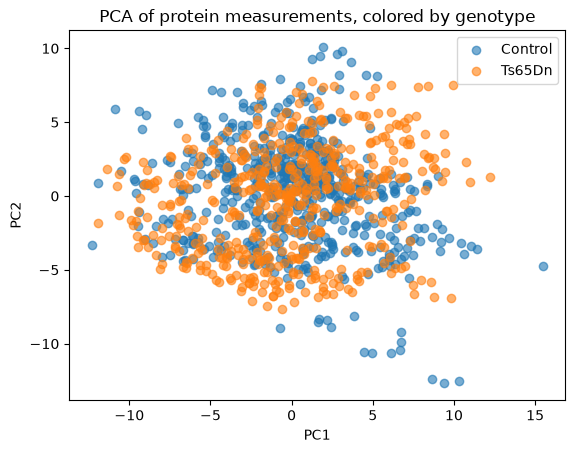

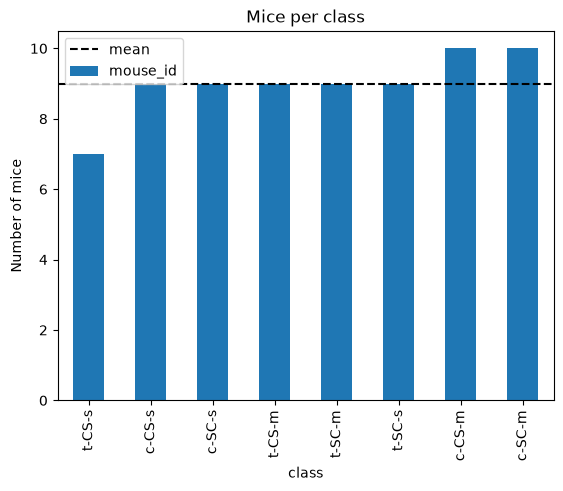

In [17]:
print("Rows and columns:", mice_raw.shape)
print("Unique mice:", mice_raw["mouse_id"].nunique())
print("Measurements per mouse:", mice_raw.groupby("mouse_id").size().unique())

for col in ["Genotype", "Treatment", "Behavior", "class"]:
    print(f"\n{col}")
    print(mice_raw[col].value_counts())

mice_per_class = mice_raw.groupby("class")["mouse_id"].nunique()
rows_per_class = mice_raw["class"].value_counts()
display(pd.DataFrame({"mice": mice_per_class, "rows": rows_per_class}))

example_protein = protein_cols[0]

for genotype, group in mice_raw.groupby("Genotype"):
    group[example_protein].hist(bins=20, alpha=0.6, label=genotype)

plt.xlabel(example_protein)
plt.ylabel("Number of measurements")
plt.title(f"{example_protein} by genotype")
plt.legend()
plt.show()

X_vis = StandardScaler().fit_transform(mice_raw[protein_cols].fillna(mice_raw[protein_cols].median()))
coords_vis = PCA(n_components=2).fit_transform(X_vis)

vis_df = pd.DataFrame({
    "PC1": coords_vis[:, 0],
    "PC2": coords_vis[:, 1],
    "Genotype": mice_raw["Genotype"].values})

for genotype, group in vis_df.groupby("Genotype"):
    plt.scatter(group["PC1"], group["PC2"], label=genotype, alpha=0.6)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of protein measurements, colored by genotype")
plt.legend()
plt.show()

mice_per_class.sort_values().plot(kind="bar")
plt.axhline(mice_per_class.mean(), color="black", linestyle="--", label="mean")
plt.xlabel("class")
plt.ylabel("Number of mice")
plt.title("Mice per class")
plt.legend()
plt.show()

Plot 1 - DYRK1A_N by genotype: does a protein differ between control and trisomic mice? Ts65Dn mice have higher expression of DYRK1A_N, potentially that could be a predictor of trisomic organism (though picked by chance as a 1st protein available).

Plot 2 - PCA by genotype: is genotype the dominant source of variation in the proteins? No: there's a significant overlap between PC1 and PC2, though there're sevetral outliers on the right upper and lower corners.

Plot 3 - is mice per class distribution balanced? `t-CS-s` has 7 mice, below the mean, while `c-CS-m` / `c-SC-m` have 10.

### 3.3 Diagnostics

Report checks for:
- missingness in proteins and metadata: 
  - 1,396 of 83,160 protein values are missing: 1.7% in 49 of the 77 proteins and 528 rows
  - most missed: BCL2_N: 285, H3MeK4_N: 270, BAD_N 213, EGR1_N 210
- duplicate rows or duplicate measurement identifiers: none
- expected 15 measurements per mouse: in place
- unusual categories or inconsistent labels: none: 2 genotypes, 2 treatments, 2 behaviors, 8 classes
- non-finite, negative, or implausible expression values: no infinite values. 1 negative value (unexpected for expression value)
- highly correlated or redundant protein variables: 10 protein pairs with r > 0.9, ARC_N and pS6_N are have r = 1.00
- predictors that are deterministic parts of the target: class is fully determined by Genotype, Treatment and Behavior, so class would leak the target Genotype.

In [11]:
top_missing = missing_by_column.sort_values(ascending=False).head(3).index

for protein in top_missing:
    print(protein, "- fraction missing by class")
    print(mice_raw.assign(missing=mice_raw[protein].isna()).groupby("class")["missing"].mean().round(2))
    print()

print("Duplicate MouseIDs:", mice_raw["MouseID"].duplicated().sum())
print("Duplicate full rows:", mice_raw.duplicated().sum())

rows_per_mouse = mice_raw.groupby("mouse_id").size()
print("Mice without exactly 15 measurements:", (rows_per_mouse != 15).sum())

for col in ["Genotype", "Treatment", "Behavior", "class"]:
    print(col, sorted(mice_raw[col].unique()))

print("\nInfinite protein values:", int(np.isinf(mice_raw[protein_cols]).sum().sum()))
protein_values = mice_raw[protein_cols].stack()
print("Negative protein values:")
print(protein_values[protein_values < 0])

corr = mice_raw[protein_cols].corr().abs()
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("\nProtein pairs with |correlation| > 0.9:", (corr_pairs > 0.9).sum())
display(corr_pairs[corr_pairs > 0.9].sort_values(ascending=False).head(10))

combo = mice_raw["Genotype"] + "|" + mice_raw["Treatment"] + "|" + mice_raw["Behavior"]
classes_per_combo = mice_raw.groupby(combo)["class"].nunique()
print("Genotype/Treatment/Behavior combinations:", classes_per_combo.shape[0])
print("Combinations mapping to more than one class:", (classes_per_combo > 1).sum())

BCL2_N - fraction missing by class
class
c-CS-m    0.20
c-CS-s    0.22
c-SC-m    0.50
c-SC-s    0.22
t-CS-m    0.11
t-CS-s    0.14
t-SC-m    0.33
t-SC-s    0.33
Name: missing, dtype: float64

H3MeK4_N - fraction missing by class
class
c-CS-m    0.40
c-CS-s    0.33
c-SC-m    0.40
c-SC-s    0.22
t-CS-m    0.22
t-CS-s    0.00
t-SC-m    0.33
t-SC-s    0.00
Name: missing, dtype: float64

BAD_N - fraction missing by class
class
c-CS-m    0.20
c-CS-s    0.33
c-SC-m    0.32
c-SC-s    0.11
t-CS-m    0.22
t-CS-s    0.00
t-SC-m    0.33
t-SC-s    0.00
Name: missing, dtype: float64

Duplicate MouseIDs: 0
Duplicate full rows: 0
Mice without exactly 15 measurements: 0
Genotype ['Control', 'Ts65Dn']
Treatment ['Memantine', 'Saline']
Behavior ['C/S', 'S/C']
class ['c-CS-m', 'c-CS-s', 'c-SC-m', 'c-SC-s', 't-CS-m', 't-CS-s', 't-SC-m', 't-SC-s']

Infinite protein values: 0
Negative protein values:
298  RRP1_N   -0.062008
dtype: float64

Protein pairs with |correlation| > 0.9: 10


ARC_N     pS6_N         1.000000
DYRK1A_N  BRAF_N        0.959578
          ITSN1_N       0.959512
NR1_N     pNR1_N        0.947872
DYRK1A_N  pERK_N        0.945719
pERK_N    BRAF_N        0.926984
ITSN1_N   BRAF_N        0.917608
NR1_N     Bcatenin_N    0.914610
pNR1_N    pNR2B_N       0.906504
ITSN1_N   pERK_N        0.906289
dtype: float64

Genotype/Treatment/Behavior combinations: 8
Combinations mapping to more than one class: 0


### 3.4 Preparation and feature roles

Selected supervised-learning question: can protein expression distinguish control from trisomic mice?

Missing-value decision: median imputation, fitted on the training split only. Removing missing values would drope too many rows.

Excluded from the features:
- `MouseID` and `mouse_id`: they identify the biological unit, so using them would leak mouse identity
- `Genotype`: target
- `class`: contains the genotype
- `Treatment`, `Behavior`: the question is whether proteins alone distinguish genotype

In [12]:
X_mice = mice_raw[protein_cols].copy()

rows_after_removal = X_mice.dropna().shape[0]
features_after_removal = X_mice.dropna(axis=1).shape[1]
print("X:", X_mice.shape, " y:", y_mice.shape)
print("Rows after complete-row removal:", rows_after_removal, "of", len(X_mice))
print("Features after removing any incomplete protein:", features_after_removal, "of", X_mice.shape[1])

role_table = pd.DataFrame({
    "column": ["MouseID", "mouse_id"] + protein_cols + ["Genotype", "Treatment", "Behavior", "class"],
    "role": (
        ["identifier (row)", "grouping variable (biological unit)"]
        + ["feature"] * len(protein_cols)
        + ["target", "excluded (conditional factor)", "excluded (conditional factor)", "excluded (derived from target)"])})

role_table.head(10)

X: (1080, 77)  y: (1080,)
Rows after complete-row removal: 552 of 1080
Features after removing any incomplete protein: 28 of 77


,column,role
0,MouseID,identifier (row)
1,mouse_id,grouping variable (biological unit)
2,DYRK1A_N,feature
3,ITSN1_N,feature
4,BDNF_N,feature
5,NR1_N,feature
6,NR2A_N,feature
7,pAKT_N,feature
8,pBRAF_N,feature
9,pCAMKII_N,feature


### 3.5 Split strategy
- Independent biological unit: `mouse`
- Grouping variable: `mouse_id`
- Split method: `GroupShuffleSplit`, 75% train / 25% test. Every mouse goes entirely to train or to test. The split is not stratified by class, could be imbalanced.

In [13]:
splitter_mice = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=RANDOM_STATE)

train_idx_mice, test_idx_mice = next(
    splitter_mice.split(
        X_mice,
        y_mice,
        groups=mice_raw["mouse_id"]))

train_mice = mice_raw.iloc[train_idx_mice].copy()
test_mice = mice_raw.iloc[test_idx_mice].copy()

print("Train rows:", train_mice.shape[0], "Train mice:", train_mice["mouse_id"].nunique())
print("Test rows:", test_mice.shape[0], "Test mice:", test_mice["mouse_id"].nunique())
print("Mouse overlap between train and test:", set(train_mice["mouse_id"]) & set(test_mice["mouse_id"]))

X_train_mice = train_mice[protein_cols].copy()
X_test_mice = test_mice[protein_cols].copy()
y_train_mice = train_mice["Genotype"].copy()
y_test_mice = test_mice["Genotype"].copy()

imputer_mice = SimpleImputer(strategy="median")
X_train_mice = pd.DataFrame(
    imputer_mice.fit_transform(X_train_mice),
    columns=protein_cols, index=X_train_mice.index)
X_test_mice = pd.DataFrame(
    imputer_mice.transform(X_test_mice),
    columns=protein_cols, index=X_test_mice.index)

print("\nX_train:", X_train_mice.shape, "missing:", X_train_mice.isna().sum().sum())
print("X_test:", X_test_mice.shape, "missing:", X_test_mice.isna().sum().sum())
print("y_train:", y_train_mice.shape, " y_test:", y_test_mice.shape)

Train rows: 810 Train mice: 54
Test rows: 270 Test mice: 18
Mouse overlap between train and test: set()

X_train: (810, 77) missing: 0
X_test: (270, 77) missing: 0
y_train: (810,)  y_test: (270,)


### 3.6 Confounding and distribution structure

Investigate associations between the target and:
- treatment 
- behavior 
- genotype 
- composite class 
- number of measurements per mouse.

In [14]:
display(pd.crosstab(mice_raw["Genotype"], mice_raw["Treatment"]))
display(pd.crosstab(mice_raw["Genotype"], mice_raw["Behavior"]))
display(pd.crosstab(mice_raw["Genotype"], mice_raw["class"]))

rows_per_mouse_by_genotype = mice_raw.groupby(["Genotype", "mouse_id"]).size()
rows_per_mouse_by_genotype.groupby("Genotype").describe()

Treatment,Memantine,Saline
Genotype,,
Control,300,270
Ts65Dn,270,240


Behavior,C/S,S/C
Genotype,,
Control,285,285
Ts65Dn,240,270


class,c-CS-m,c-CS-s,c-SC-m,c-SC-s,t-CS-m,t-CS-s,t-SC-m,t-SC-s
Genotype,,,,,,,,
Control,150,135,150,135,0,0,0,0
Ts65Dn,0,0,0,0,135,105,135,135


,count,mean,std,min,25%,50%,75%,max
Genotype,,,,,,,,
Control,38.0,15.0,0.0,15.0,15.0,15.0,15.0,15.0
Ts65Dn,34.0,15.0,0.0,15.0,15.0,15.0,15.0,15.0


**Discussion**

- `Treatment` and `Behavior` alook like kind of balanced within `Genotype`, with caveats (control has 300 Memantine and 270 Saline rows, Ts65Dn 270 and 240). `t-CS-s` has only 7 mice against 9-10 in the other classes.
- `class` encodes `Genotype` directly (Section 3.3), so it must never be used as a feature when the target is `Genotype`.
- Every mouse contributes exactly 15 rows, so no mouse dominates through repeated sampling. There are 38 Control and 34 Ts65Dn mice.
- Missingness differs between classes for several proteins. A model could use which values are missing as a proxy for the experimental group, so a missingness indicator should not be used as a feature.

## Summary

- **ML question:** can protein expression distinguish control from trisomic mice?
- **Biological unit:** the mouse (`mouse_id`), with 15 measurements each; 72 mice and 1080 rows.
- **Split:** group-aware split on `mouse_id` (54 training mice, 18 test mice, no overlap), with median imputation fitted on the training data only.
- **Remaining concerns:**
  - `t-CS-s` has only 7 mice, and the split is not stratified by class;
  - missingness varies by class;
  - 10 protein pairs have |r| > 0.9 (redundant features);
  - one negative expression value;
  - some control measurements are outlier scmpared to the rest in the PCA,  may be batch or technical effects, not biology;
  - units, normalization and detection limits are not documented in the file.